# Описание кейса из kaggle 

Данный набор данных был любезно предоставлен компанией Olist — крупнейшим оператором, объединяющим продавцов на различных торговых площадках Бразилии. Olist помогает представителям малого бизнеса со всей страны выходить на каналы продаж без лишних сложностей, предлагая единый договор. Продавцы могут реализовывать свои товары через платформу Olist и отправлять их покупателям напрямую, используя логистических партнеров компании. Подробнее — на нашем сайте: www.olist.com

После того как клиент совершает покупку через Olist, продавец получает уведомление о необходимости выполнить заказ. Когда товар доставлен (или наступает ожидаемая дата доставки), покупателю по электронной почте приходит опрос, в котором он может оценить свой опыт покупки и оставить комментарий.

Важное примечание
Один заказ может включать несколько товаров.
Каждый товар может быть предоставлен отдельным продавцом.
Все названия магазинов и партнеров в тексте были заменены на названия великих домов из «Игры престолов».

# Первичный просмотр и предобработка данных Olist
Кейс 1: «Исследование факторов, влияющих на своевременную доставку и удовлетворённость клиентов».

На этом этапе мы загружаем таблицы, смотрим, что в них есть, ищем пропуски, дубликаты и странные значения, и разбираемся, как таблицы связаны между собой. Глубокий анализ — на следующих этапах.

Данные: [Brazilian E-Commerce Public Dataset by Olist (Kaggle)](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce). CSV-файлы нужно положить в папку `data/`. Таблица геолокации большая, поэтому хранится в архиве `olist_geolocation_dataset.zip` — pandas читает его без распаковки.

In [1]:
import pandas as pd

DATA_DIR = 'data/'
files = {
    'orders':    'olist_orders_dataset.csv',
    'items':     'olist_order_items_dataset.csv',
    'reviews':   'olist_order_reviews_dataset.csv',
    'payments':  'olist_order_payments_dataset.csv',
    'customers': 'olist_customers_dataset.csv',
    'products':  'olist_products_dataset.csv',
    'sellers':   'olist_sellers_dataset.csv',
    'cat_tr':    'product_category_name_translation.csv',
}
df = {name: pd.read_csv(DATA_DIR + f) for name, f in files.items()}

In [2]:
df['geo'] = pd.read_csv(DATA_DIR + 'olist_geolocation_dataset.csv')

## 1. Размер таблиц и столбцы

In [3]:
for name, t in df.items():
    print(f'{name}: {t.shape[0]} строк, {t.shape[1]} столбцов')
    print('   ', list(t.columns))

orders: 99441 строк, 8 столбцов
    ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']
items: 112650 строк, 7 столбцов
    ['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']
reviews: 99224 строк, 7 столбцов
    ['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']
payments: 103886 строк, 5 столбцов
    ['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']
customers: 99441 строк, 5 столбцов
    ['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']
products: 32951 строк, 9 столбцов
    ['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'produc

## 2. Пропуски

In [4]:
for name, t in df.items():
    na = t.isna().sum()
    na = na[na > 0]
    if len(na):
        print(f'--- {name}')
        print(na.to_string())

--- orders
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
--- reviews
review_comment_title      87656
review_comment_message    58247
--- products
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2


## 3. Дубликаты

In [5]:
for name, t in df.items():
    print(f'{name}: полных дубликатов строк — {t.duplicated().sum()}')
print()
print('Заказов с несколькими товарами:', (df['items'].groupby('order_id').size() > 1).sum())
print('Заказов с несколькими оплатами:', (df['payments'].groupby('order_id').size() > 1).sum())
print('Заказов с несколькими отзывами:', (df['reviews'].groupby('order_id').size() > 1).sum())

orders: полных дубликатов строк — 0
items: полных дубликатов строк — 0
reviews: полных дубликатов строк — 0
payments: полных дубликатов строк — 0
customers: полных дубликатов строк — 0
products: полных дубликатов строк — 0
sellers: полных дубликатов строк — 0
cat_tr: полных дубликатов строк — 0
geo: полных дубликатов строк — 261831

Заказов с несколькими товарами: 9803
Заказов с несколькими оплатами: 2961
Заказов с несколькими отзывами: 547


## 4. Статусы заказов и даты
Даты хранятся как текст — переводим в формат даты.

In [6]:
orders = df['orders'].copy()
date_cols = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
             'order_delivered_customer_date', 'order_estimated_delivery_date']
for c in date_cols:
    orders[c] = pd.to_datetime(orders[c])

print(orders['order_status'].value_counts().to_string())
print()
print('Период покупок:', orders['order_purchase_timestamp'].min().date(), '—', orders['order_purchase_timestamp'].max().date())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2

Период покупок: 2016-09-04 — 2018-10-17


In [7]:
orders['order_purchase_timestamp'].dt.to_period('M').value_counts().sort_index()

order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, Name: count, dtype: int64

## 5. Странные значения в датах

In [8]:
dl = orders[orders['order_status'] == 'delivered']
print('Доставленных заказов:', len(dl))
print('Доставлены, но нет даты доставки:', dl['order_delivered_customer_date'].isna().sum())
print('Передача перевозчику раньше покупки:', (dl['order_delivered_carrier_date'] < dl['order_purchase_timestamp']).sum())
print('Доставка покупателю раньше передачи перевозчику:', (dl['order_delivered_customer_date'] < dl['order_delivered_carrier_date']).sum())

Доставленных заказов: 96478
Доставлены, но нет даты доставки: 8
Передача перевозчику раньше покупки: 165
Доставка покупателю раньше передачи перевозчику: 23


## 6. Как связаны таблицы
Главная таблица — заказы (`order_id`). К ней по `order_id` присоединяются товары, оплаты и отзывы, по `customer_id` — покупатели. Товары связаны с карточками товаров (`product_id`) и продавцами (`seller_id`). Геолокация связана с покупателями и продавцами только через префикс почтового индекса (`zip_code_prefix`).

In [9]:
o_ids = set(orders['order_id'])
print('order_id уникален в заказах:', orders['order_id'].is_unique)
print('Товары без заказа:', (~df['items']['order_id'].isin(o_ids)).sum())
print('Отзывы без заказа:', (~df['reviews']['order_id'].isin(o_ids)).sum())
print('Заказы без покупателя:', (~orders['customer_id'].isin(df['customers']['customer_id'])).sum())
print('Товары без продавца:', (~df['items']['seller_id'].isin(df['sellers']['seller_id'])).sum())

order_id уникален в заказах: True
Товары без заказа: 0
Отзывы без заказа: 0
Заказы без покупателя: 0
Товары без продавца: 0


## 7. Таблица геолокации
В таблице координаты (широта и долгота) для префиксов почтовых индексов. Она может пригодиться, чтобы посчитать расстояние между продавцом и покупателем.

In [10]:
geo = df['geo']
print('Строк:', len(geo), '| уникальных индексов:', geo['geolocation_zip_code_prefix'].nunique())
print('Полных дубликатов:', geo.duplicated().sum())
in_brazil = geo['geolocation_lat'].between(-33.8, 5.3) & geo['geolocation_lng'].between(-74, -34.7)
print('Координаты за пределами Бразилии:', (~in_brazil).sum())
zips = set(geo['geolocation_zip_code_prefix'])
print('Покупатели, чьего индекса нет в геолокации:', (~df['customers']['customer_zip_code_prefix'].isin(zips)).sum())
print('Продавцы, чьего индекса нет в геолокации:', (~df['sellers']['seller_zip_code_prefix'].isin(zips)).sum())
print('Примеры написания Сан-Паулу:', list(geo.loc[geo['geolocation_city'].str.contains('paulo') & (geo['geolocation_state'] == 'SP'), 'geolocation_city'].unique()[:4]))

Строк: 1000163 | уникальных индексов: 19015
Полных дубликатов: 261831
Координаты за пределами Бразилии: 42
Покупатели, чьего индекса нет в геолокации: 278
Продавцы, чьего индекса нет в геолокации: 7
Примеры написания Сан-Паулу: ['sao paulo', 'são paulo', 'sãopaulo', 'sa£o paulo']


## Что мы поняли
- Таблицы связываются между собой без потерь.
- В одном заказе может быть несколько товаров, оплат и отзывов — перед объединением их нужно свести к одной строке на заказ, иначе суммы задвоятся.
- Даты нужно переводить из текста в формат даты.
- Для анализа доставки подходят заказы со статусом `delivered` и известной датой доставки.
- В начале (2016) и в конце (сентябрь–октябрь 2018) периода заказов очень мало — эти месяцы, скорее всего, уберём.
- Есть небольшое число заказов со странными датами — нужно решить, удалять ли их.
- У части товаров нет категории.
- В геолокации много дубликатов, есть ошибочные координаты за пределами Бразилии и разное написание городов. На один индекс приходится много точек — если будем считать расстояния, нужно свести их к одной точке на индекс (например, среднее).

**Следующий шаг:** объединить таблицы и создать признаки (опоздание, срок доставки, доставка в другой штат и т. д.). Решить в команде, используем ли расстояние до покупателя.

# Объединение таблиц

In [11]:
df_orders = df['orders']
df_order_items = df['items']
df_order_reviews = df['reviews']
df_order_payments = df['payments']
df_sellers = df['sellers']
df_customers = df['customers']
df_products  = df['products']
df_category_name = df['cat_tr']
df_geo = df['geo']

В этом наборе данных содержится информация о клиенте и его местоположении. 

В нашей системе каждому заказу присваивается уникальный `customer_id`. 
Это означает, что один и тот же клиент может иметь разные идентификаторы для разных заказов. Наличие в наборе данных поля `customer_unique_id` позволяет выявлять клиентов, совершавших повторные покупки в магазине. В противном случае каждый заказ выглядел бы так, будто он сделан отдельным, уникальным клиентом.

Пожалуйста, ознакомьтесь со схемой данных:

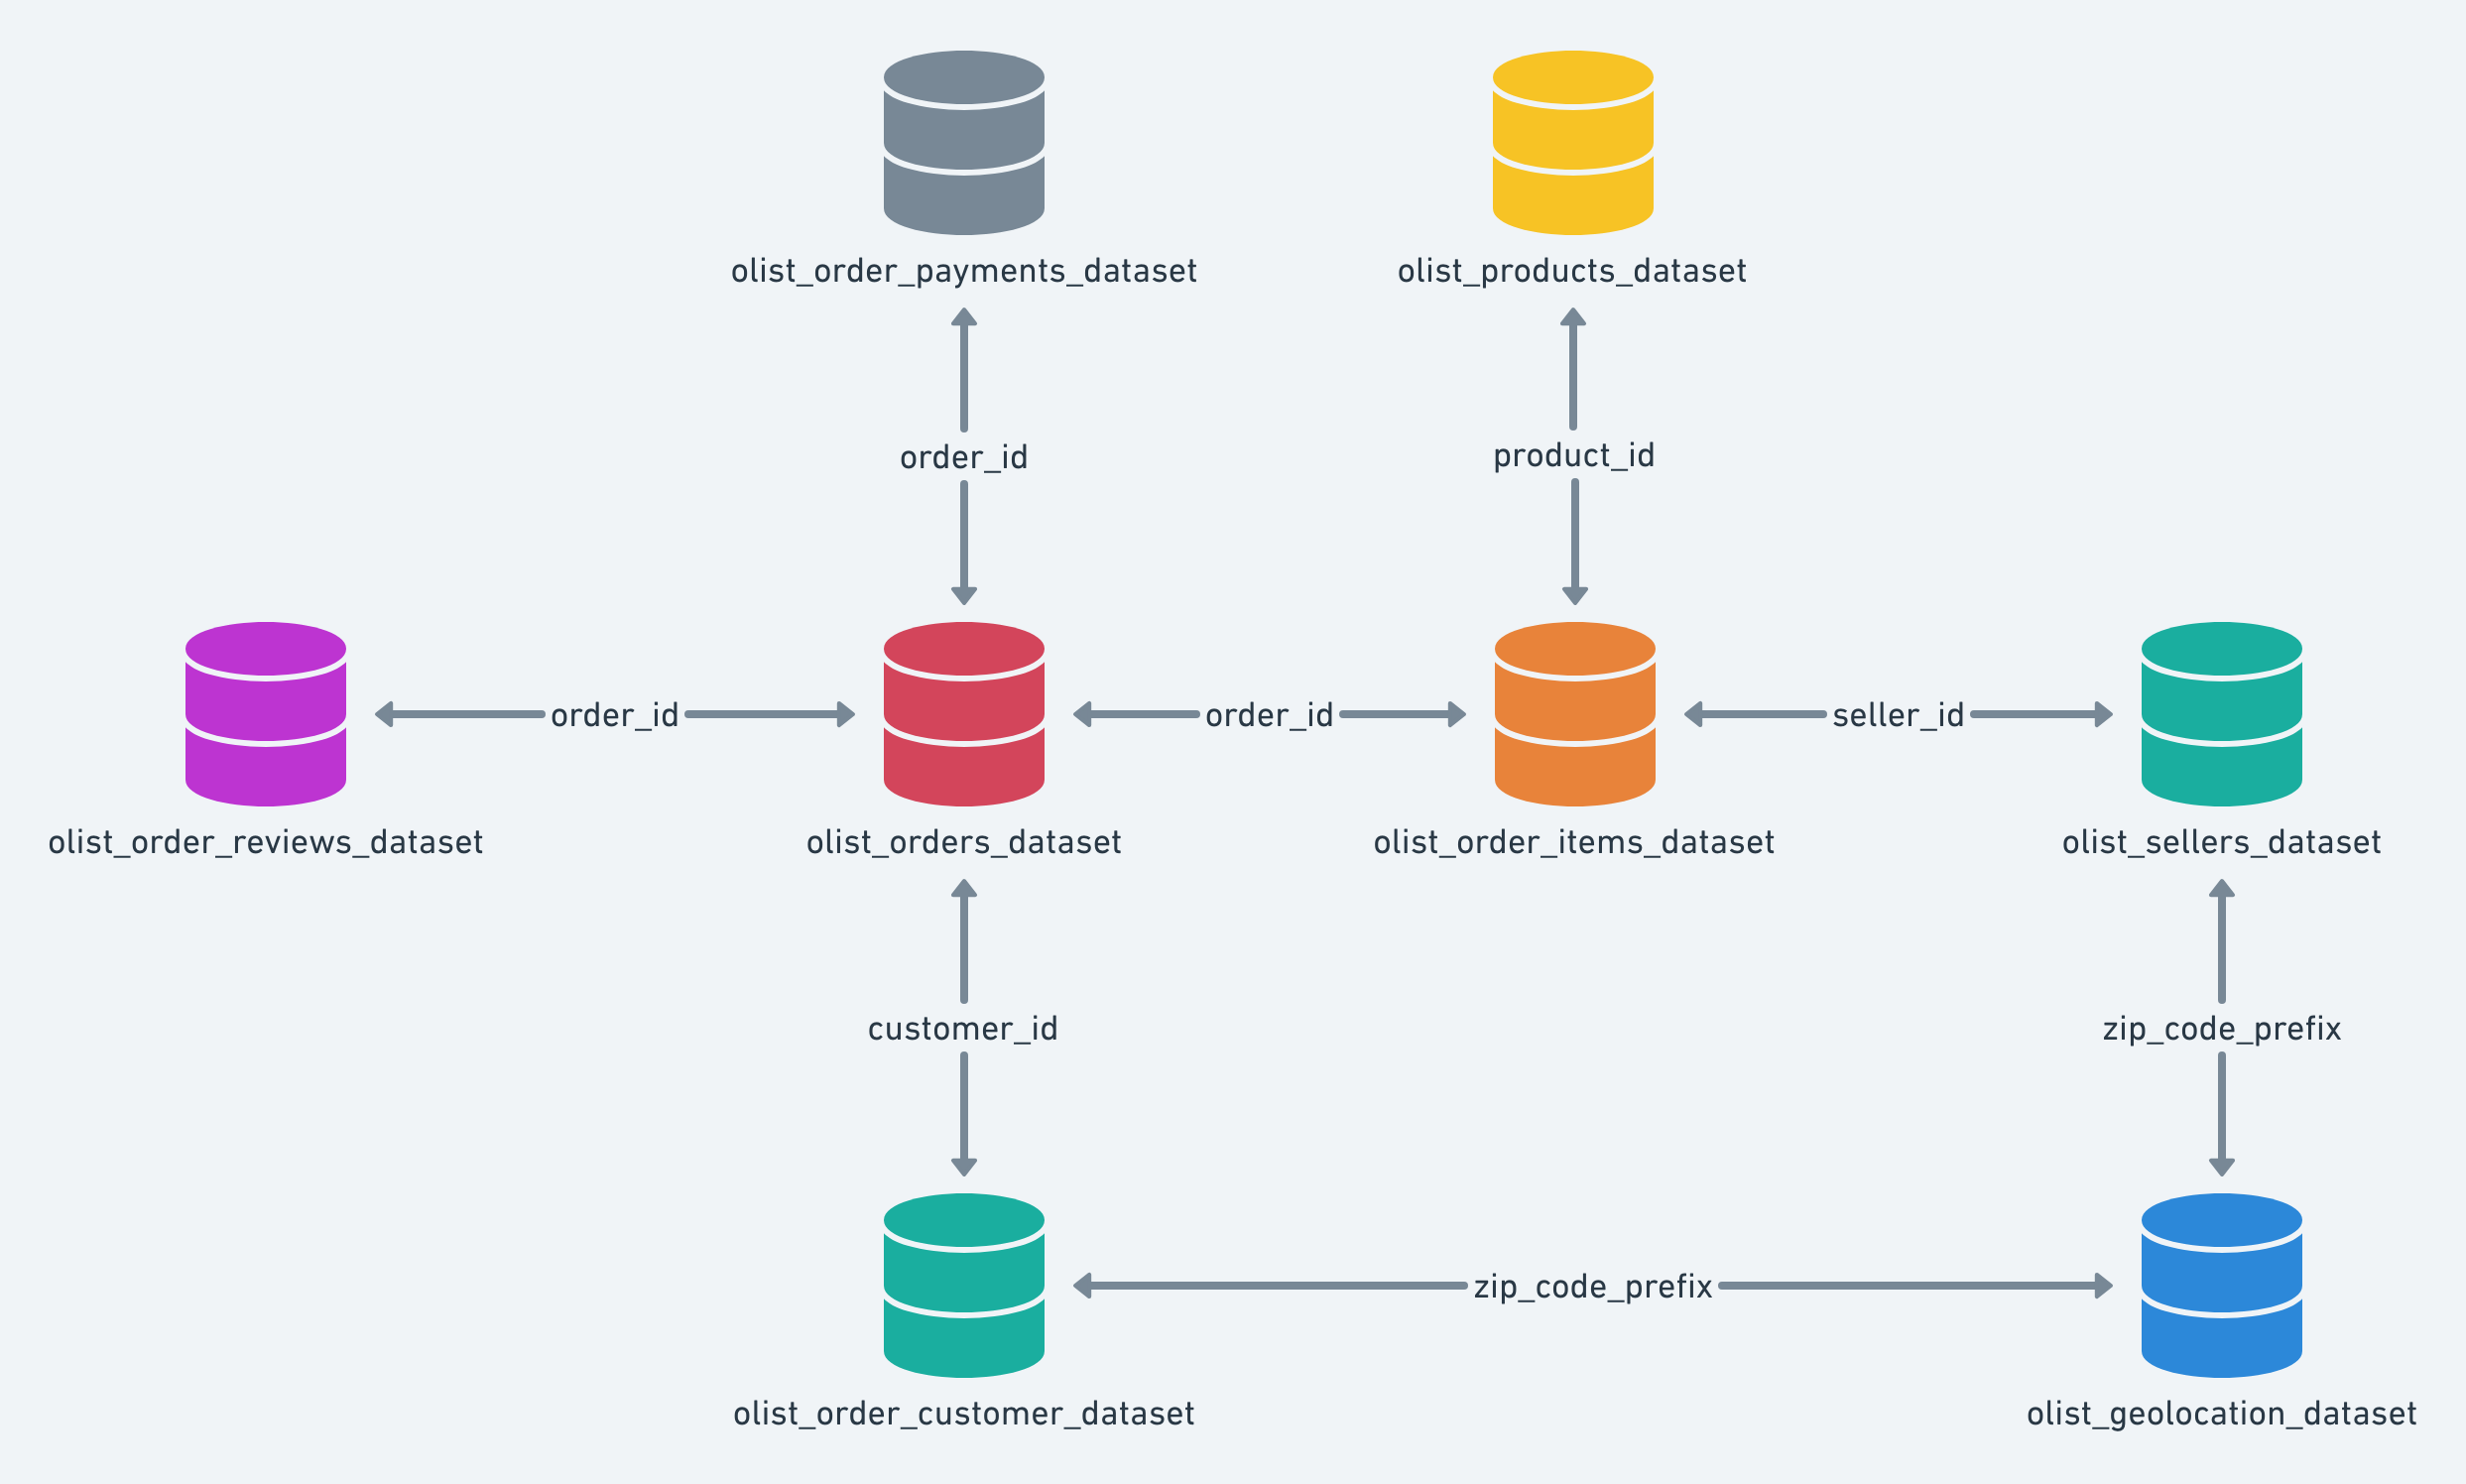

### Соединение заказов и продуктов

In [12]:
df_orders.info()
df_orders.describe()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99441,99441,99441,99441,99281,97658,96476,99441
unique,99441,99441,8,98875,90733,81018,95664,459
top,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2018-03-31 15:08:21,2018-02-27 04:31:10,2018-05-09 15:48:00,2018-05-14 20:02:44,2017-12-20 00:00:00
freq,1,1,96478,3,9,47,3,522


In [13]:
df_order_items.info()
df_order_items.describe()

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 18.4 MB


,order_item_id,price,freight_value
count,112650.000000,112650.000000,112650.000000
mean,1.197834,120.653739,19.990320
std,0.705124,183.633928,15.806405
min,1.000000,0.850000,0.000000
25%,1.000000,39.900000,13.080000
50%,1.000000,74.990000,16.260000
75%,1.000000,134.900000,21.150000
max,21.000000,6735.000000,409.680000


In [14]:
df_orders_full = df_orders.merge(df_order_items, how='left', on='order_id')
df_orders_full.info()
df_orders_full.describe()

<class 'pandas.DataFrame'>
RangeIndex: 113425 entries, 0 to 113424
Data columns (total 14 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   order_id                       113425 non-null  str    
 1   customer_id                    113425 non-null  str    
 2   order_status                   113425 non-null  str    
 3   order_purchase_timestamp       113425 non-null  str    
 4   order_approved_at              113264 non-null  str    
 5   order_delivered_carrier_date   111457 non-null  str    
 6   order_delivered_customer_date  110196 non-null  str    
 7   order_estimated_delivery_date  113425 non-null  str    
 8   order_item_id                  112650 non-null  float64
 9   product_id                     112650 non-null  str    
 10  seller_id                      112650 non-null  str    
 11  shipping_limit_date            112650 non-null  str    
 12  price                          112650 non

,order_item_id,price,freight_value
count,112650.000000,112650.000000,112650.000000
mean,1.197834,120.653739,19.990320
std,0.705124,183.633928,15.806405
min,1.000000,0.850000,0.000000
25%,1.000000,39.900000,13.080000
50%,1.000000,74.990000,16.260000
75%,1.000000,134.900000,21.150000
max,21.000000,6735.000000,409.680000


In [15]:
df_orders_products = df_orders_full.merge(df_products, how='left', on='product_id')
df_orders_products.info()
df_orders_products.describe()

<class 'pandas.DataFrame'>
RangeIndex: 113425 entries, 0 to 113424
Data columns (total 22 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   order_id                       113425 non-null  str    
 1   customer_id                    113425 non-null  str    
 2   order_status                   113425 non-null  str    
 3   order_purchase_timestamp       113425 non-null  str    
 4   order_approved_at              113264 non-null  str    
 5   order_delivered_carrier_date   111457 non-null  str    
 6   order_delivered_customer_date  110196 non-null  str    
 7   order_estimated_delivery_date  113425 non-null  str    
 8   order_item_id                  112650 non-null  float64
 9   product_id                     112650 non-null  str    
 10  seller_id                      112650 non-null  str    
 11  shipping_limit_date            112650 non-null  str    
 12  price                          112650 non

,order_item_id,price,freight_value,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,112650.000000,112650.000000,112650.000000,111047.000000,111047.000000,111047.000000,112632.000000,112632.000000,112632.000000,112632.000000
mean,1.197834,120.653739,19.990320,48.775978,787.867029,2.209713,2093.672047,30.153669,16.593766,22.996546
std,0.705124,183.633928,15.806405,10.025581,652.135608,1.721438,3751.596884,16.153449,13.443483,11.707268
min,1.000000,0.850000,0.000000,5.000000,4.000000,1.000000,0.000000,7.000000,2.000000,6.000000
25%,1.000000,39.900000,13.080000,42.000000,348.000000,1.000000,300.000000,18.000000,8.000000,15.000000
50%,1.000000,74.990000,16.260000,52.000000,603.000000,1.000000,700.000000,25.000000,13.000000,20.000000
75%,1.000000,134.900000,21.150000,57.000000,987.000000,3.000000,1800.000000,38.000000,20.000000,30.000000
max,21.000000,6735.000000,409.680000,76.000000,3992.000000,20.000000,40425.000000,105.000000,105.000000,118.000000


In [16]:
df_orders_products.tail(5)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,...,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
113420,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02 00:00:00,1.0,f1d4ce8c6dd66c47bbaa8c6781c2a923,...,174.90,20.10,bebes,52.0,828.0,4.0,4950.0,40.0,10.0,40.0
113421,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27 00:00:00,1.0,b80910977a37536adeddd63663f916ad,...,205.99,65.02,eletrodomesticos_2,51.0,500.0,2.0,13300.0,32.0,90.0,22.0
113422,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00,1.0,d1c427060a0f73f6b889a5c7c61f2ac4,...,179.99,40.59,informatica_acessorios,59.0,1893.0,1.0,6550.0,20.0,20.0,20.0
113423,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00,2.0,d1c427060a0f73f6b889a5c7c61f2ac4,...,179.99,40.59,informatica_acessorios,59.0,1893.0,1.0,6550.0,20.0,20.0,20.0
113424,66dea50a8b16d9b4dee7af250b4be1a5,edb027a75a1449115f6b43211ae02a24,delivered,2018-03-08 20:57:30,2018-03-09 11:20:28,2018-03-09 22:11:59,2018-03-16 13:08:30,2018-04-03 00:00:00,1.0,006619bbed68b000c8ba3f8725d5409e,...,68.50,18.36,beleza_saude,45.0,569.0,1.0,150.0,16.0,7.0,15.0


In [17]:
df_orders_products.isna().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 161
order_delivered_carrier_date     1968
order_delivered_customer_date    3229
order_estimated_delivery_date       0
order_item_id                     775
product_id                        775
seller_id                         775
shipping_limit_date               775
price                             775
freight_value                     775
product_category_name            2378
product_name_lenght              2378
product_description_lenght       2378
product_photos_qty               2378
product_weight_g                  793
product_length_cm                 793
product_height_cm                 793
product_width_cm                  793
dtype: int64

### Соединение продавцов и геолокации

В бразильской системе почтовых индексов (CEP) первые 5 цифр (geolocation_zip_code_prefix в датасете) определяют город и конкретный район, а таблица гео содержит в себе на один код сразу несколько географических координат. При джойне с другими таблицами сильно размножит строки датасета, во избежание чего усредним координаты по geolocation_zip_code_prefix.

In [19]:
df_geo.info()
df_geo.nunique()

<class 'pandas.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  str    
 4   geolocation_state            1000163 non-null  str    
dtypes: float64(2), int64(1), str(2)
memory usage: 50.1 MB


geolocation_zip_code_prefix     19015
geolocation_lat                717360
geolocation_lng                717613
geolocation_city                 8011
geolocation_state                  27
dtype: int64

In [20]:
df_geo.tail(5)

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
1000158,99950,-28.068639,-52.010705,tapejara,RS
1000159,99900,-27.877125,-52.224882,getulio vargas,RS
1000160,99950,-28.071855,-52.014716,tapejara,RS
1000161,99980,-28.388932,-51.846871,david canabarro,RS
1000162,99950,-28.070104,-52.018658,tapejara,RS


In [21]:
df_geo_avg_code = (df_geo.groupby('geolocation_zip_code_prefix', as_index=False)
    .agg(geolocation_lat=('geolocation_lat', 'median'),geolocation_lng=('geolocation_lng', 'median') ))
df_geo_avg_code.nunique()

geolocation_zip_code_prefix    19015
geolocation_lat                18990
geolocation_lng                18990
dtype: int64

In [22]:
df_sellers_geo = df_sellers.merge(df_geo_avg_code,
    how='left', left_on='seller_zip_code_prefix', right_on='geolocation_zip_code_prefix')

In [23]:
df_sellers_geo.tail(10)

,seller_id,seller_zip_code_prefix,seller_city,seller_state,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng
3085,9d489893ff6af05029671b785f54b998,13613,leme,SP,13613.0,-22.181937,-47.403982
3086,725af026f869236a8dd0ceb98564d156,35530,claudio,MG,35530.0,-20.441593,-44.765888
3087,f00f5b35d0abcacbdd863672f4bb2c1a,1238,sao paulo,SP,1238.0,-23.542944,-46.653267
3088,7bac63f6603d382cc8d0832eb6c100a8,5713,sao paulo,SP,5713.0,-23.626508,-46.729985
3089,f1fdf2d13186575751aa25876536d85c,5314,sao paulo,SP,5314.0,-23.529228,-46.736541
3090,98dddbc4601dd4443ca174359b237166,87111,sarandi,PR,87111.0,-23.448778,-51.869229
3091,f8201cab383e484733266d1906e2fdfa,88137,palhoca,SC,88137.0,-27.626457,-48.673749
3092,74871d19219c7d518d0090283e03c137,4650,sao paulo,SP,4650.0,-23.657838,-46.677462
3093,e603cf3fec55f8697c9059638d6c8eb5,96080,pelotas,RS,96080.0,-31.751451,-52.323899
3094,9e25199f6ef7e7c347120ff175652c3b,12051,taubate,SP,12051.0,-23.011362,-45.585644


**Выбор доставленных заказов и признак опоздания**

In [24]:
# работаем с копией, исходная таблица df_orders остаётся без изменений
orders = df_orders.copy()

# даты записаны как текст - переводим в формат даты
date_cols = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
             'order_delivered_customer_date', 'order_estimated_delivery_date']
for col in date_cols:
    orders[col] = pd.to_datetime(orders[col])

print('Всего заказов:', len(orders))
print()
print(orders['order_status'].value_counts().to_string())

Всего заказов: 99441

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2


In [66]:
# для анализа опозданий нужны заказы, которые доставлены и у которых есть дата доставки
delivered_h = orders[(orders['order_status'] == 'delivered') &
                   (orders['order_delivered_customer_date'].notna())].copy()
print('Доставленных заказов с датой доставки:', len(delivered_h))

# опоздание: дата получения позже обещанной даты (сравниваем календарные даты, как просил заказчик)
delivered_h['is_late'] = (delivered_h['order_delivered_customer_date'].dt.normalize() >
                        delivered_h['order_estimated_delivery_date'].dt.normalize()).astype(int)

print('Опоздало заказов:', delivered_h['is_late'].sum())
print('Доля опозданий, %:', round(delivered_h['is_late'].mean() * 100, 2))

Доставленных заказов с датой доставки: 96470
Опоздало заказов: 6534
Доля опозданий, %: 6.77


Вывод: для анализа остаются 96 470 доставленных заказов. Заказы без доставки (отменённые, в пути и др.) не берём: опоздание для них посчитать нельзя. Опоздала примерно каждая пятнадцатая посылка.

**Описательная статистика для доставленных заказов**

Посморим на основные характеристики поставленных заказов:

In [72]:
# 1. Подтягиваем вес каждого товара из df['products'] и считаем на уровне заказа
items_with_weight = df['items'].merge(
    df['products'][['product_id', 'product_weight_g']],
    on='product_id',
    how='left',
)

order_physical = (
    items_with_weight.groupby('order_id')
    .agg(
        items_count=('order_item_id', 'count'),
        total_weight_g=('product_weight_g', 'sum'),
    )
    .reset_index()
)

# 2. Присоединяем к orders_metrics без дублей
orders_metrics = orders_metrics.drop(
    columns=['items_count', 'total_weight_g'], errors='ignore'
).merge(order_physical, on='order_id', how='left')

# 3. Формируем таблицу основных показателей (среднее и медиана)
cols = [
    'delivery_days',
    'items_price',
    'freight_value',
    'total_order_value',
    'items_count',
    'total_weight_g',
    'review_score',
]

labels = {
    'delivery_days': 'Срок доставки (дней)',
    'items_price': 'Стоимость товаров в заказе (BRL)',
    'freight_value': 'Стоимость доставки (BRL)',
    'total_order_value': 'Общая сумма заказа (BRL)',
    'items_count': 'Количество товаров в заказе (шт.)',
    'total_weight_g': 'Вес заказа (г)',
    'review_score': 'Оценка покупателя (1–5)',
}

summary_stats = pd.DataFrame({
    'Показатель': [labels[c] for c in cols],
    'Среднее (Mean)': [round(orders_metrics[c].mean(), 2) for c in cols],
    'Медиана (Median)': [round(orders_metrics[c].median(), 2) for c in cols],
    'Мин': [round(orders_metrics[c].min(), 2) for c in cols],
    'Макс': [round(orders_metrics[c].max(), 2) for c in cols],
})

display(summary_stats)

,Показатель,Среднее (Mean),Медиана (Median),Мин,Макс
0,Срок доставки (дней),12.56,10.22,0.53,209.63
1,Стоимость товаров в заказе (BRL),137.04,86.50,0.85,13440.00
2,Стоимость доставки (BRL),22.79,17.17,0.00,1794.96
3,Общая сумма заказа (BRL),159.83,105.28,9.59,13664.08
4,Количество товаров в заказе (шт.),1.14,1.00,1.00,21.00
5,Вес заказа (г),2386.47,750.00,0.00,184400.00
6,Оценка покупателя (1–5),4.16,5.00,1.00,5.00


Распределение заказов и опозданий по месяцам:

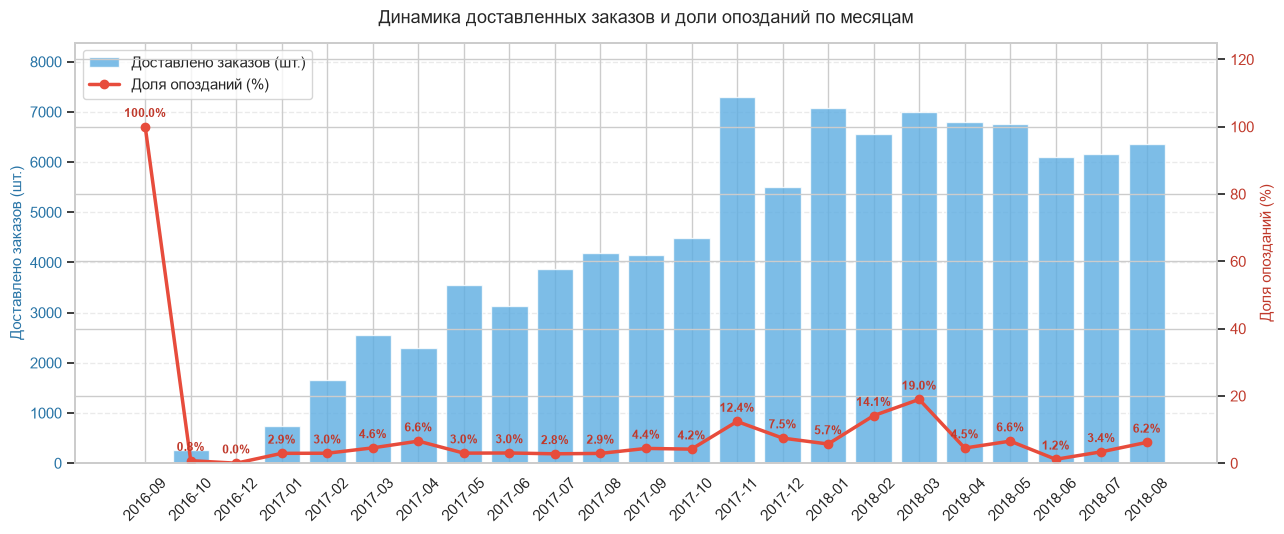

In [80]:
import matplotlib.pyplot as plt

# Берём все доставленные заказы без фильтрации по количеству
plot_df = monthly_stats.copy()

fig, ax1 = plt.subplots(figsize=(13, 5.5))

# --- 1. Столбцы (левая ось Y): количество доставленных заказов ---
bars = ax1.bar(
    plot_df['purchase_month'],
    plot_df['delivered_count'],
    color='#5dade2',
    alpha=0.8,
    label='Доставлено заказов (шт.)',
)
ax1.set_ylabel('Доставлено заказов (шт.)', color='#2874a6', fontsize=11)
ax1.tick_params(axis='y', labelcolor='#2874a6')
ax1.tick_params(axis='x', rotation=45)
ax1.set_ylim(0, plot_df['delivered_count'].max() * 1.15)

# --- 2. Линия (правая ось Y): процент опозданий ---
ax2 = ax1.twinx()
line = ax2.plot(
    plot_df['purchase_month'],
    plot_df['late_rate_pct'],
    color='#e74c3c',
    marker='o',
    linewidth=2.5,
    markersize=6,
    label='Доля опозданий (%)',
)
ax2.set_ylabel('Доля опозданий (%)', color='#c0392b', fontsize=11)
ax2.tick_params(axis='y', labelcolor='#c0392b')
ax2.set_ylim(0, plot_df['late_rate_pct'].max() * 1.25)

# Подписываем значения процентов над точками линии
for x, y in zip(plot_df['purchase_month'], plot_df['late_rate_pct']):
  ax2.annotate(
      f'{y:.1f}%',
      xy=(x, y),
      xytext=(0, 7),
      textcoords='offset points',
      ha='center',
      fontsize=8.5,
      fontweight='bold',
      color='#c0392b',
  )

# Общий заголовок и легенда
plt.title(
    'Динамика доставленных заказов и доли опозданий по месяцам',
    fontsize=13,
    pad=14,
)
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(
    lines_1 + lines_2,
    labels_1 + labels_2,
    loc='upper left',
    frameon=True,
    facecolor='white',
)

ax1.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

Виден рост доли опозданий в периоды:
- ноябрь 2017 наблюдается увеличение числа заказов и резкий рост доли опозданий.
- февраль-март 2018  при стабильном потоке заказов, доля опозданий достигла исторического максимума.
- 2016 год показывает выброс, но его не принимаем во внимание по причине малого количества заказов.

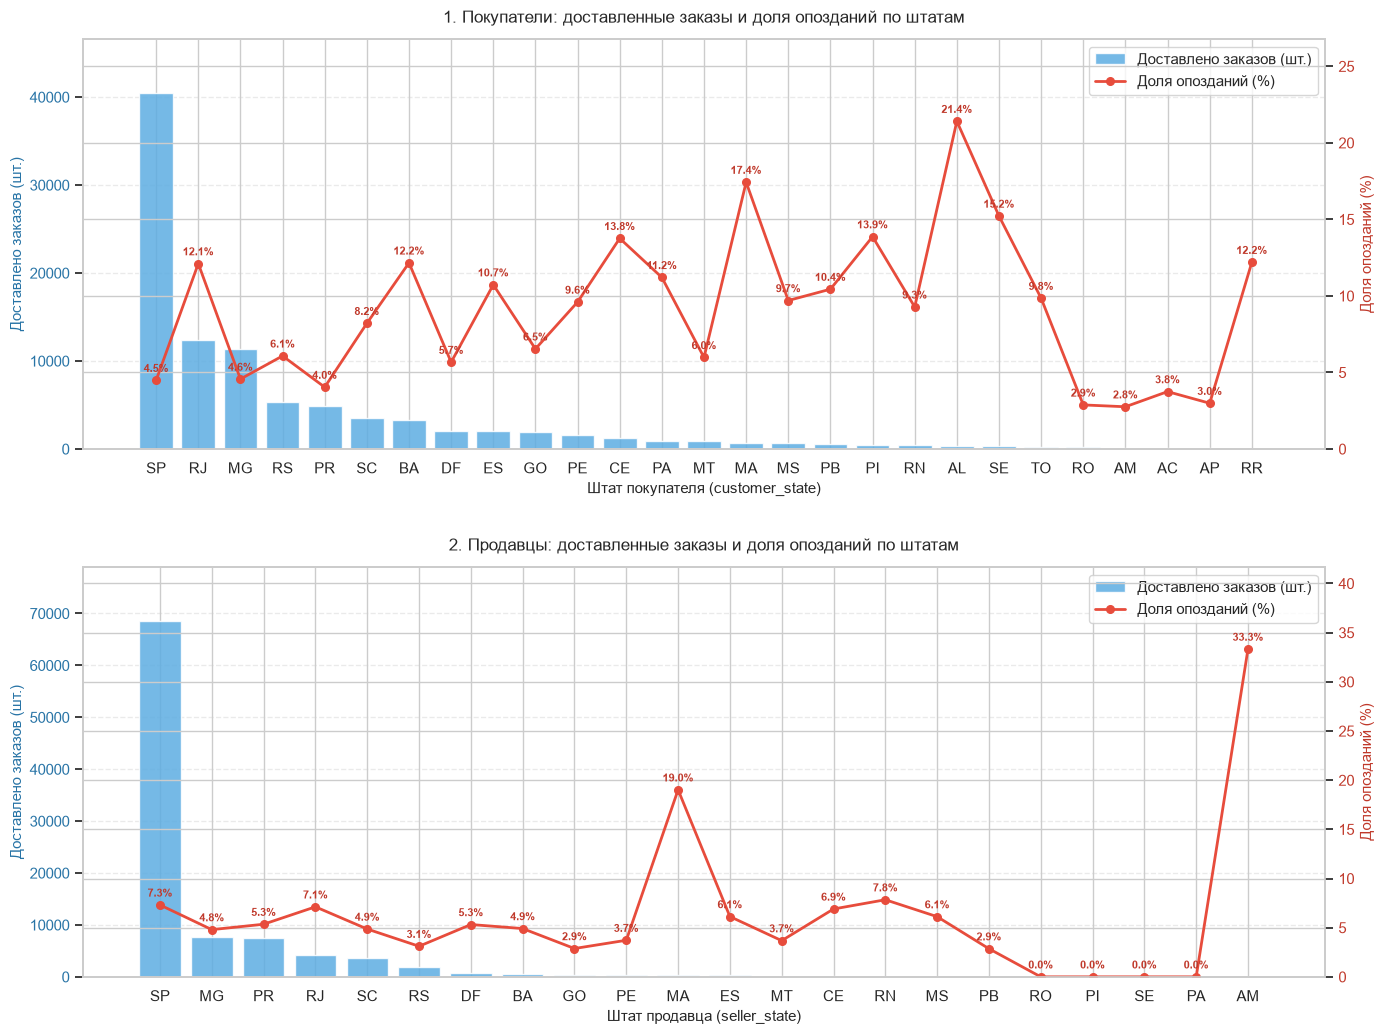

In [74]:
# 1. Агрегация по штатам ПОКУПАТЕЛЕЙ
cust_stats = (
    delivered_h.merge(
        df['customers'][['customer_id', 'customer_state']],
        on='customer_id',
        how='left',
    )
    .groupby('customer_state')
    .agg(
        delivered_count=('order_id', 'count'),
        late_rate_pct=('is_late', lambda x: round(x.mean() * 100, 2)),
    )
    .reset_index()
    .rename(columns={'customer_state': 'state'})
    .sort_values('delivered_count', ascending=False)
)

# 2. Агрегация по штатам ПРОДАВЦОВ (уникальные заказы на штат)
sell_stats = (
    delivered_h[['order_id', 'is_late']]
    .merge(df['items'][['order_id', 'seller_id']], on='order_id', how='inner')
    .merge(
        df['sellers'][['seller_id', 'seller_state']],
        on='seller_id',
        how='left',
    )[['order_id', 'seller_state', 'is_late']]
    .drop_duplicates()
    .groupby('seller_state')
    .agg(
        delivered_count=('order_id', 'count'),
        late_rate_pct=('is_late', lambda x: round(x.mean() * 100, 2)),
    )
    .reset_index()
    .rename(columns={'seller_state': 'state'})
    .sort_values('delivered_count', ascending=False)
)


# 3. Функция отрисовки одного комбо-графика (столбцы + линия)
def plot_state_combo(ax1, data, title, xlabel):
  ax1.bar(
      data['state'],
      data['delivered_count'],
      color='#5dade2',
      alpha=0.85,
      label='Доставлено заказов (шт.)',
  )
  ax1.set_ylabel('Доставлено заказов (шт.)', color='#2874a6', fontsize=10.5)
  ax1.tick_params(axis='y', labelcolor='#2874a6')
  ax1.set_xlabel(xlabel, fontsize=10.5)
  ax1.set_ylim(0, data['delivered_count'].max() * 1.15)
  ax1.grid(axis='y', linestyle='--', alpha=0.4)

  ax2 = ax1.twinx()
  ax2.plot(
      data['state'],
      data['late_rate_pct'],
      color='#e74c3c',
      marker='o',
      linewidth=2,
      markersize=5.5,
      label='Доля опозданий (%)',
  )
  ax2.set_ylabel('Доля опозданий (%)', color='#c0392b', fontsize=10.5)
  ax2.tick_params(axis='y', labelcolor='#c0392b')
  ax2.set_ylim(0, data['late_rate_pct'].max() * 1.25)

  for x, y in zip(data['state'], data['late_rate_pct']):
    ax2.annotate(
        f'{y:.1f}%',
        xy=(x, y),
        xytext=(0, 6),
        textcoords='offset points',
        ha='center',
        fontsize=8,
        fontweight='bold',
        color='#c0392b',
    )

  ax1.set_title(title, fontsize=12.5, pad=12)
  lines_1, labels_1 = ax1.get_legend_handles_labels()
  lines_2, labels_2 = ax2.get_legend_handles_labels()
  ax1.legend(
      lines_1 + lines_2,
      labels_1 + labels_2,
      loc='upper right',
      frameon=True,
      facecolor='white',
  )


# 4. Создаём полотно из 2 графиков друг под другом
fig, (ax_top, ax_bottom) = plt.subplots(2, 1, figsize=(14, 10.5))

plot_state_combo(
    ax_top,
    cust_stats,
    '1. Покупатели: доставленные заказы и доля опозданий по штатам',
    'Штат покупателя (customer_state)',
)

plot_state_combo(
    ax_bottom,
    sell_stats,
    '2. Продавцы: доставленные заказы и доля опозданий по штатам',
    'Штат продавца (seller_state)',
)

plt.tight_layout(h_pad=2.5)
plt.show()

Количество заказов распределено между штатами неравномерно, доля опозданий сильно разнится от штата к штату, наиболее высокие показатели в отдаленных малонаселенных регионах.

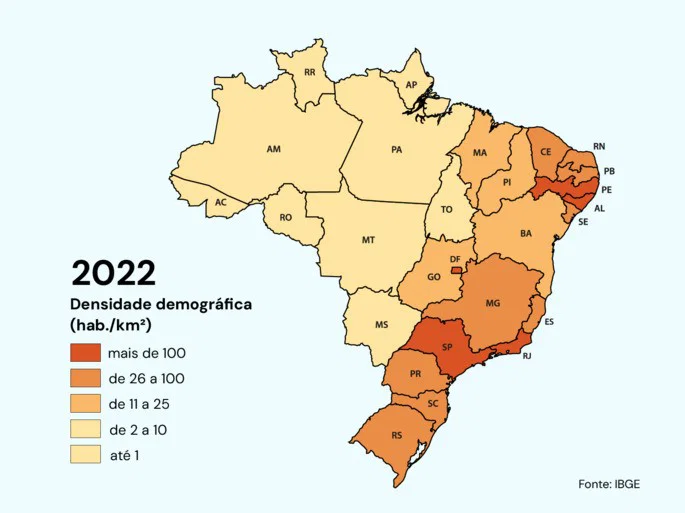

**Гипотезы и дальнейшие шаги**

**Основной вопрос задачи**

Какие факторы влияют на вероятность своевременной доставки заказа? Как можно было бы ее повысить?

**Гипотезы для проверки**

Гипотеза 1. влияют ли на своевременность доставки географические факторы - Анастасия, Иван
- расстояние между продавцом и покупателем по координатам
- штат и город покупателя и продавца
- доставка внутри одного штата или в другой штат

Гипотеза 2. влияют ли на своевременность доставки характеристики продавца - Александра
- задержка передачи заказа перевозчику относительно срока отгрузки
- доля опозданий у каждого продавца
- продавцы которые систематически отправляют заказы позже срока
- число заказов у продавца (продавцов с малым числом заказов не учитываем?) штат продавца?)

Гипотеза 3. влияют ли на своевременность доставки характеристики заказа - Дарья, Алина
- вес и размеры товара
- объем и вес посылки в заказе
- число товаров в заказе
- категория товара
- стоимость доставки


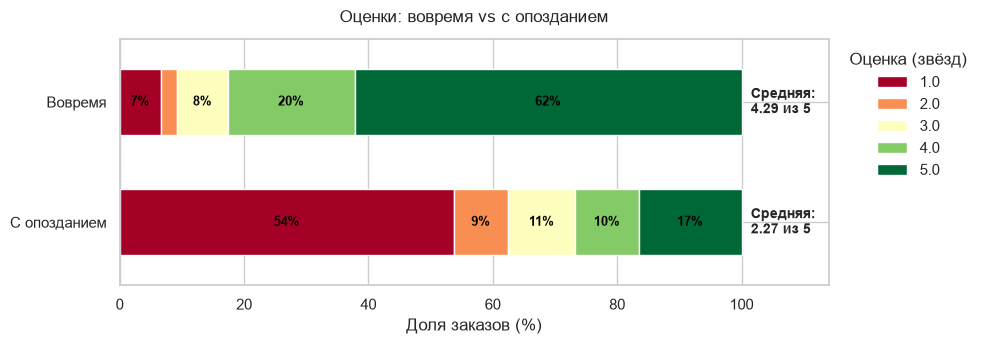

In [56]:
# 1. Считаем доли оценок по группам (в %)
score_ct = (
    pd.crosstab(df_vis['status_label'], df_vis['score_round'], normalize='index')
    * 100
)
order = ['С опозданием', 'Вовремя']
score_ct = score_ct.reindex([row for row in order if row in score_ct.index])

# 2. Считаем среднюю оценку для каждой группы
means = df_vis.groupby('status_label')['review_score'].mean()

# 3. Строим горизонтальный Stacked Bar
ax = score_ct.plot(
    kind='barh',
    stacked=True,
    figsize=(10, 3.6),
    colormap='RdYlGn',  # от красного (1 звезда) к зелёному (5 звёзд)
    width=0.55,
)

plt.title('Оценки: вовремя vs с опозданием', fontsize=12, pad=12)
plt.xlabel('Доля заказов (%)')
plt.ylabel('')
plt.xlim(0, 114)  # запас справа, чтобы поместилась подпись со средней оценкой
plt.legend(
    title='Оценка (звёзд)',
    bbox_to_anchor=(1.01, 1),
    loc='upper left',
    frameon=False,
)

# Подписываем доли (%) внутри сегментов шире 6%
for c in ax.containers:
  labels = [f'{v:.0f}%' if v > 6 else '' for v in c.datavalues]
  ax.bar_label(
      c,
      labels=labels,
      label_type='center',
      fontsize=9.5,
      fontweight='bold',
      color='black',
  )

# Добавляем среднюю оценку справа от каждой полосы
for i, status in enumerate(score_ct.index):
  mean_val = means[status]
  ax.text(
      101.5,
      i,
      f'Средняя:\n{mean_val:.2f} из 5',
      va='center',
      ha='left',
      fontsize=10,
      fontweight='bold',
  )

plt.tight_layout()
plt.show()

Оценки для заказов с опозданием значительно ниже в сравнении с доставленными вовремя.

**Гипотезы и дальнейшие шаги**

**Основной вопрос задачи**

Какие факторы влияют на вероятность своевременной доставки заказа? Как можно было бы ее повысить?

**Гипотезы для проверки**

Гипотеза 1. влияют ли на своевременность доставки географические факторы - Анастасия, Иван
- расстояние между продавцом и покупателем по координатам
- штат и город покупателя и продавца
- доставка внутри одного штата или в другой штат

Гипотеза 2. влияют ли на своевременность доставки характеристики продавца - Александра
- задержка передачи заказа перевозчику относительно срока отгрузки
- доля опозданий у каждого продавца
- продавцы которые систематически отправляют заказы позже срока
- число заказов у продавца (продавцов с малым числом заказов не учитываем?) штат продавца?

Гипотеза 3. влияют ли на своевременность доставки характеристики заказа - Дарья, Алина
- вес и размеры товара
- объем и вес посылки в заказе
- число товаров в заказе
- категория товара
- стоимость доставки